# Part 1 – Preprocessing (tasks 1.1 and 1.2)

Run order: **this notebook first**, then `2_glm.ipynb`.
All paths come from `paths.py`. Outputs go to `Data1/derivatives/preprocessed_data/`, figures to `figures/` (both git-ignored).

The two long steps (`fsl_anat` ≈ 15 min, `mcflirt`) are skipped automatically if their output already exists.
Before pushing: **Edit → Clear Outputs of All Cells**, then save.

In [1]:
import os, sys, glob, subprocess
import os.path as op
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist
from paths import *

import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
loadFSL()

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from fsl.wrappers import fast, flirt, mcflirt
from nilearn import plotting, image

mni_brain_1mm = op.expandvars("$FSLDIR/data/standard/MNI152_T1_1mm_brain.nii.gz")
mni_head_2mm  = op.expandvars("$FSLDIR/data/standard/MNI152_T1_2mm.nii.gz")
mni_brain_2mm = op.expandvars("$FSLDIR/data/standard/MNI152_T1_2mm_brain.nii.gz")
cuts = (-30, -20, 10)   # same slices in every figure, so rows are comparable

print("Data:", DATA_ROOT, "| T1 found:", op.exists(ANAT_PATH), "| fMRI found:", op.exists(FUNC_PATH))

Data: /data/Desktop/myfiles/Data1 | T1 found: True | fMRI found: True


In [2]:
%gui wx


(ipykernel_launcher.py:879): dbind-WARNING **: 10:40:03.872: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/203555172/at-spi/bus_100: No such file or directory


In [3]:
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

10:40:05: Debug: Adding duplicate image handler for 'Windows bitmap file'
10:40:05: Debug: Adding duplicate animation handler for '1' type
10:40:05: Debug: Adding duplicate animation handler for '2' type
10:40:05: Debug: Adding duplicate image handler for 'Windows bitmap file'
10:40:05: Debug: Adding duplicate animation handler for '1' type
10:40:05: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:879): Gtk-CRITICAL **: 10:40:06.225: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:879): Gtk-CRITICAL **: 10:40:08.433: gtk_window_resize: assertion 'width > 0' failed


## 1.1 Structural preprocessing
Quality control first: the MNI contours already follow the T1 closely → the HCP T1 is provided in MNI space (0.7 mm).

Shape: (260, 311, 260) | voxel size: (np.float32(0.7), np.float32(0.7), np.float32(0.7))


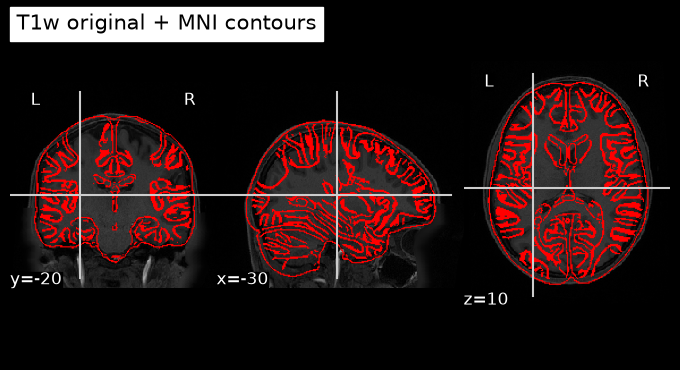

In [4]:
img = image.load_img(ANAT_PATH)
print("Shape:", img.shape, "| voxel size:", img.header.get_zooms())
d = plotting.plot_anat(ANAT_PATH, title="T1w original + MNI contours", cut_coords=cuts)
d.add_edges(mni_brain_1mm)

### 1.1a Skull-stripping (BET, robust centre estimation, f = 0.5)

In [5]:
betted_brain = op.join(ANAT_OUT, "T1w_brain")
os.system('bet {} {} -m -R'.format(ANAT_PATH, betted_brain))   # 0 = success

0

In [6]:
# QC: mask on the original T1 (look at frontal / superior parietal regions, cerebellum)
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(ANAT_PATH)
fsleyesDisplay.load(betted_brain + "_mask")

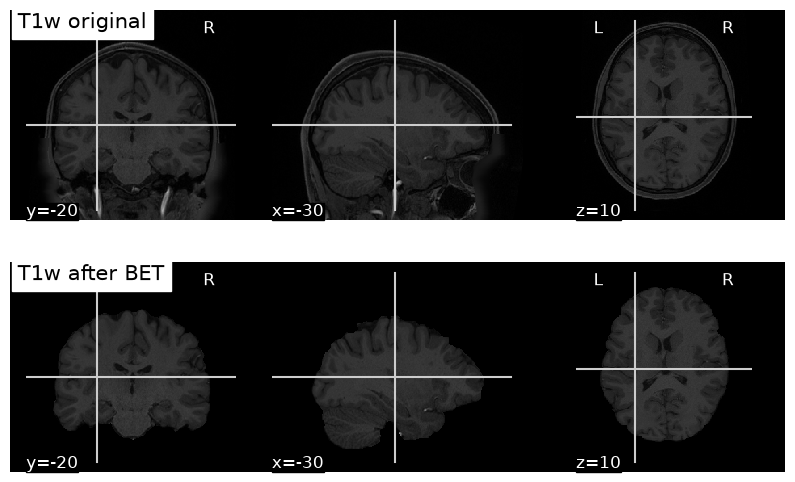

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
plotting.plot_anat(ANAT_PATH, title="T1w original", cut_coords=cuts, axes=axes[0])
plotting.plot_anat(betted_brain + ".nii.gz", title="T1w after BET", cut_coords=cuts, axes=axes[1])
plt.savefig(op.join(FIG_DIR, "1a_skullstrip.png"), dpi=200, bbox_inches="tight")

### 1.1b Segmentation (FAST, 3 classes: pve_0 = CSF, pve_1 = GM, pve_2 = WM)

In [8]:
segmentation_path = op.join(ANAT_OUT, "T1w_fast")
fast(imgs=[betted_brain], out=segmentation_path, n_classes=3)

{}

In [9]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(betted_brain)
for i, cmap in enumerate(["Red", "Green", "Blue"]):
    fsleyesDisplay.load(f"{segmentation_path}_pve_{i}")
    fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[i + 1]).cmap = cmap

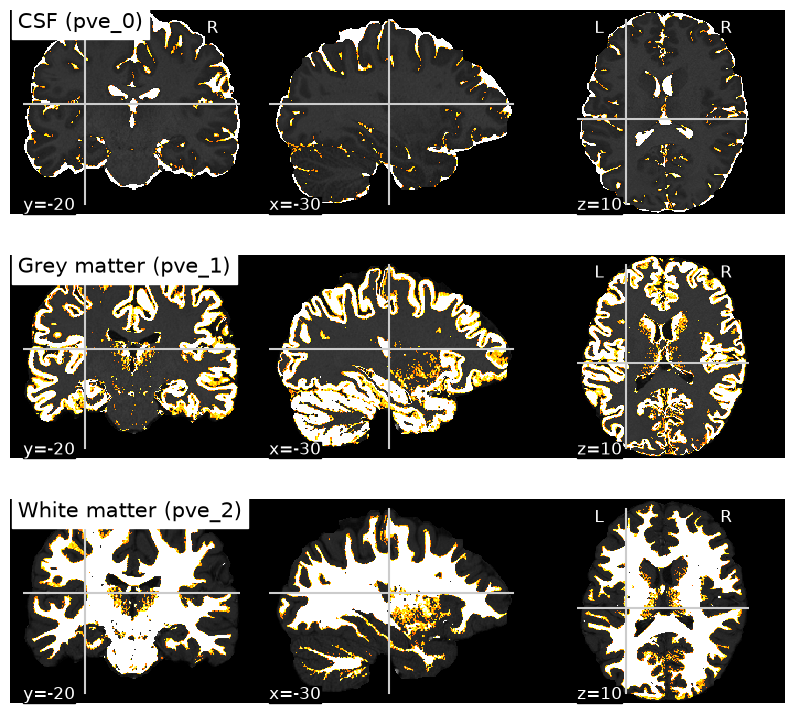

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
names = ["CSF (pve_0)", "Grey matter (pve_1)", "White matter (pve_2)"]
for i, name in enumerate(names):
    plotting.plot_stat_map(f"{segmentation_path}_pve_{i}.nii.gz", bg_img=betted_brain + ".nii.gz",
                           title=name, cmap="hot", threshold=0.5, colorbar=False,
                           cut_coords=cuts, axes=axes[i])
plt.savefig(op.join(FIG_DIR, "1b_segmentation.png"), dpi=200, bbox_inches="tight")

### 1.1c Registration to MNI – linear (FLIRT, 12 dof)

In [11]:
t1_mni_flirt = op.join(ANAT_OUT, "T1w_brain_mni")
flirt(betted_brain, mni_brain_1mm, out=t1_mni_flirt, omat=op.join(ANAT_OUT, "T1w2mni.mat"))

{}

In [12]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_brain_1mm)
fsleyesDisplay.load(t1_mni_flirt)

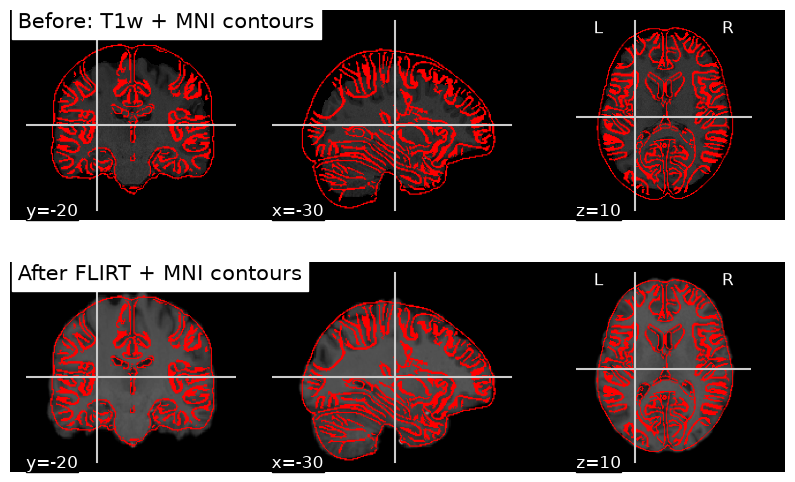

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
d = plotting.plot_anat(betted_brain + ".nii.gz", title="Before: T1w + MNI contours", cut_coords=cuts, axes=axes[0])
d.add_edges(mni_brain_1mm)
d = plotting.plot_anat(t1_mni_flirt + ".nii.gz", title="After FLIRT + MNI contours", cut_coords=cuts, axes=axes[1])
d.add_edges(mni_brain_1mm)
plt.savefig(op.join(FIG_DIR, "1c_registration_flirt.png"), dpi=200, bbox_inches="tight")

### 1.1c Registration – linear vs non-linear (fsl_anat = FLIRT + FNIRT, 2 mm MNI)
FNIRT expects the T1 **with** skull, so `fsl_anat` gets the original T1. ≈ 15 min, skipped if already done.

In [14]:
if not op.exists(op.join(FSL_ANAT_DIR, "T1_to_MNI_nonlin.nii.gz")):
    os.system('fsl_anat -i {} -o {} --clobber --nosubcortseg'.format(ANAT_PATH, op.join(ANAT_OUT, "fsl_anat")))
else:
    print("fsl_anat already done:", FSL_ANAT_DIR)

Wed Oct 28 10:49:47 UTC 2026
Reorienting to standard orientation
Wed Oct 28 10:50:00 UTC 2026
Automatically cropping the image
Starting Single Image Segmentation
T1-weighted image
Imagesize : 260 x 311 x 221
Pixelsize : 0.7 x 0.7 x 0.7

1 6.40003
2 6.58691
3 6.80277
KMeans Iteration 0
KMeans Iteration 1
KMeans Iteration 2
KMeans Iteration 3
KMeans Iteration 4
KMeans Iteration 5
KMeans Iteration 6
KMeans Iteration 7
KMeans Iteration 8
KMeans Iteration 9
KMeans Iteration 10
KMeans Iteration 11
KMeans Iteration 12
KMeans Iteration 13
KMeans Iteration 14
Tanaka Iteration 0 bias field 10
Tanaka-inner-loop-iteration=0 MRFWeightsTotal=6.34411e+07 beta=0.02
Tanaka-inner-loop-iteration=1 MRFWeightsTotal=6.45342e+07 beta=0.02
Tanaka-inner-loop-iteration=2 MRFWeightsTotal=6.45645e+07 beta=0.02
Tanaka-inner-loop-iteration=3 MRFWeightsTotal=6.45654e+07 beta=0.02
Tanaka-inner-loop-iteration=4 MRFWeightsTotal=6.45655e+07 beta=0.02
 CLASS 1 MEAN 402.525 STDDEV 286.756 CLASS 2 MEAN 699.783 STDDEV 71.62

In [15]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_head_2mm)
fsleyesDisplay.load(op.join(FSL_ANAT_DIR, "T1_to_MNI_lin"))
fsleyesDisplay.load(op.join(FSL_ANAT_DIR, "T1_to_MNI_nonlin"))

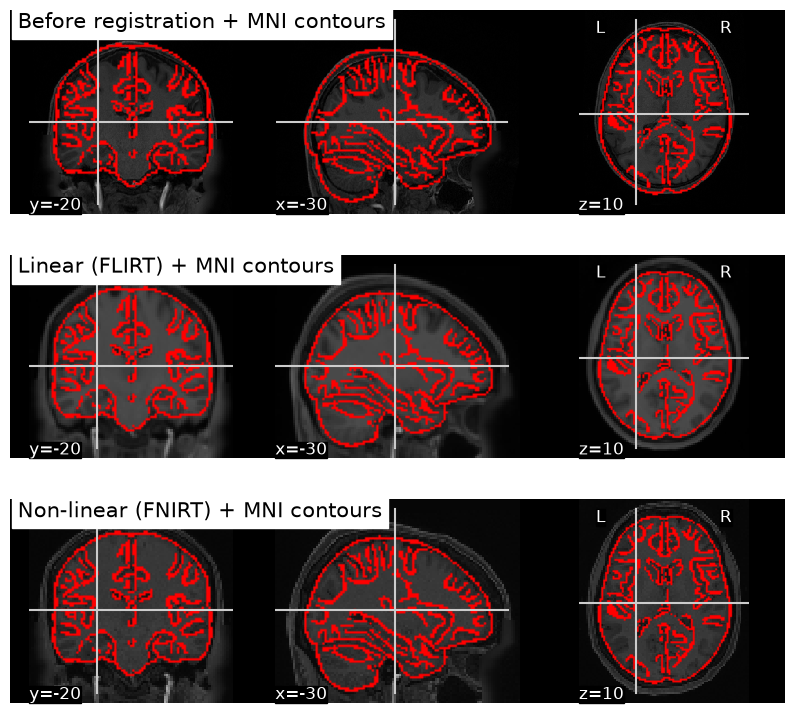

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
rows = [(ANAT_PATH, "Before registration + MNI contours"),
        (op.join(FSL_ANAT_DIR, "T1_to_MNI_lin.nii.gz"), "Linear (FLIRT) + MNI contours"),
        (op.join(FSL_ANAT_DIR, "T1_to_MNI_nonlin.nii.gz"), "Non-linear (FNIRT) + MNI contours")]
for ax, (path, title) in zip(axes, rows):
    d = plotting.plot_anat(path, title=title, cut_coords=cuts, axes=ax)
    d.add_edges(mni_brain_2mm)
plt.savefig(op.join(FIG_DIR, "1c_registration_lin_vs_nonlin.png"), dpi=200, bbox_inches="tight")

## 1.2 Functional preprocessing
### 1.2a Motion correction (MCFLIRT, 6 dof, reference = middle volume) + framewise displacement (Power)

In [17]:
func_img = nib.load(FUNC_PATH)
n_vols = func_img.shape[-1]
print("fMRI shape:", func_img.shape, "| voxel size + TR:", func_img.header.get_zooms())

if not op.exists(MOTION_PAR):
    mcflirt(infile=FUNC_PATH, o=MOCO_PATH, plots=True, report=True, dof=6, mats=False)
else:
    print("mcflirt already done:", MOCO_PATH)

fMRI shape: (91, 109, 91, 316) | voxel size + TR: (np.float32(2.0), np.float32(2.0), np.float32(2.0), np.float32(0.72))


Processed data will be saved as /data/Desktop/myfiles/Data1/derivatives/preprocessed_data/func/bold_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [158] to 8 mm pixels
Registering volumes ... [159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][30

refnum = 158
Original_refvol = -1


Registering volumes ... [159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][305][306][307][308][309][310][311][312][313][314][315][157][156][155][154][153][152][151][150][149][148][147][146][145][144][143][142][141][140][139][138][137][136][135][134][133][132][131][130][129][128][127][126][125][124][123][122][121][120][

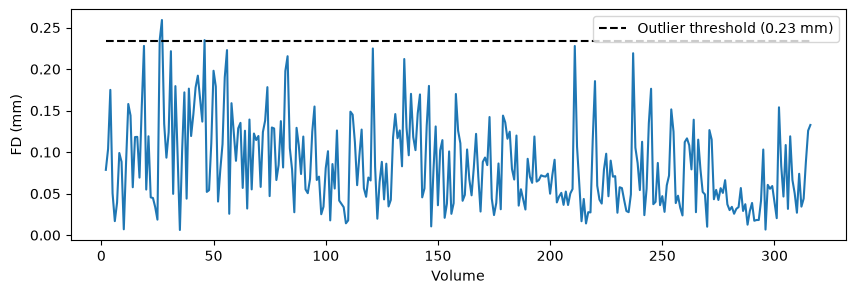

mean FD: 0.085 mm | max: 0.259 mm
Volumes over the threshold: [26, 27, 46]


In [18]:
def load_mot_params_fsl_6_dof(path):
    return pd.read_csv(path, sep=r"\s+", header=None,
                       names=['Rotation x', 'Rotation y', 'Rotation z',
                              'Translation x', 'Translation y', 'Translation z'])

def compute_FD_power(mot_params):
    diff = mot_params.diff().iloc[1:]
    rots = diff[['Rotation x', 'Rotation y', 'Rotation z']] * 50      # radians -> mm on a 50 mm sphere
    trans = diff[['Translation x', 'Translation y', 'Translation z']]
    return rots.abs().sum(axis=1) + trans.abs().sum(axis=1)

mot_params = load_mot_params_fsl_6_dof(MOTION_PAR)
fd = compute_FD_power(mot_params).to_numpy()
q1, q3 = np.quantile(fd, [0.25, 0.75])
threshold = q3 + 1.5 * (q3 - q1)          # outlier threshold (Tukey)

vols = np.arange(2, fd.size + 2)           # FD[i] = displacement between volume i and i+1 (1-based)
plt.figure(figsize=(10, 3))
plt.plot(vols, fd)
plt.hlines(threshold, vols[0], vols[-1], colors='black', linestyles='dashed', label=f'Outlier threshold ({threshold:.2f} mm)')
plt.xlabel('Volume'); plt.ylabel('FD (mm)'); plt.legend()
plt.savefig(op.join(FIG_DIR, "2a_FD.png"), dpi=200, bbox_inches="tight")
plt.show()

print(f"mean FD: {fd.mean():.3f} mm | max: {fd.max():.3f} mm")
print("Volumes over the threshold:", vols[fd > threshold].tolist())

### 1.2b Gaussian smoothing (FWHM = 6 mm, i.e. 3 × the 2 mm voxel size)
`fslmaths -s` takes sigma, not FWHM: sigma = FWHM / 2.3548.

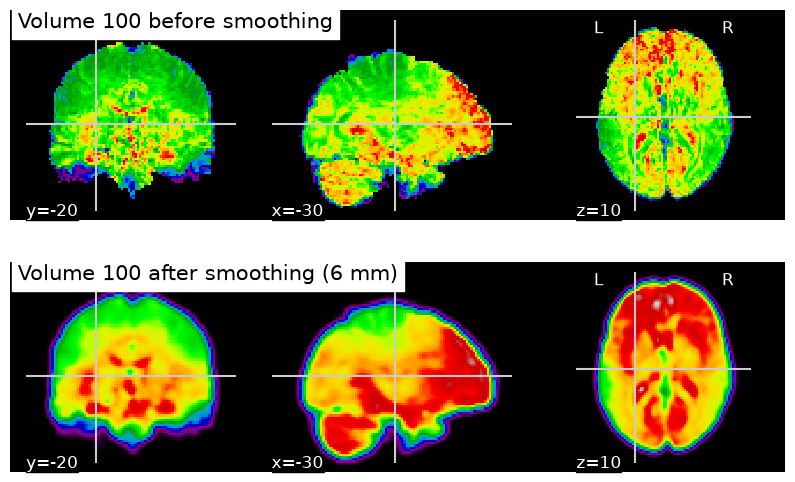

In [19]:
if not op.exists(SMOOTH_PATH + ".nii.gz"):
    subprocess.run(["fslmaths", MOCO_PATH, "-s", str(FWHM / 2.3548), SMOOTH_PATH], check=True)

vol = 100
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
plotting.plot_epi(image.index_img(MOCO_PATH + ".nii.gz", vol), title=f"Volume {vol} before smoothing",
                  cut_coords=cuts, axes=axes[0])
plotting.plot_epi(image.index_img(SMOOTH_PATH + ".nii.gz", vol), title=f"Volume {vol} after smoothing ({FWHM} mm)",
                  cut_coords=cuts, axes=axes[1])
plt.savefig(op.join(FIG_DIR, "2b_smoothing.png"), dpi=200, bbox_inches="tight")

### 1.2c Alignment between functional and anatomical data
Both the HCP T1 and the fMRI are already in MNI space, so we overlay them **without any registration**.
If the T1 contours follow the fMRI brain, the functional → anatomical registration (and normalisation) step can be skipped (question 2c).

*An earlier version used `epi_reg` + `applywarp` with the T1→MNI warp. It was removed: the fMRI is already in MNI space, so applying the warp would transform it twice (still in the git history if needed).*

fMRI affine:
 [[  -2.    0.    0.   90.]
 [   0.    2.    0. -126.]
 [   0.    0.    2.  -72.]
 [   0.    0.    0.    1.]]
T1 affine:
 [[  -0.69999999    0.            0.           90.        ]
 [   0.            0.69999999    0.         -126.        ]
 [   0.            0.            0.69999999  -72.        ]
 [   0.            0.            0.            1.        ]]


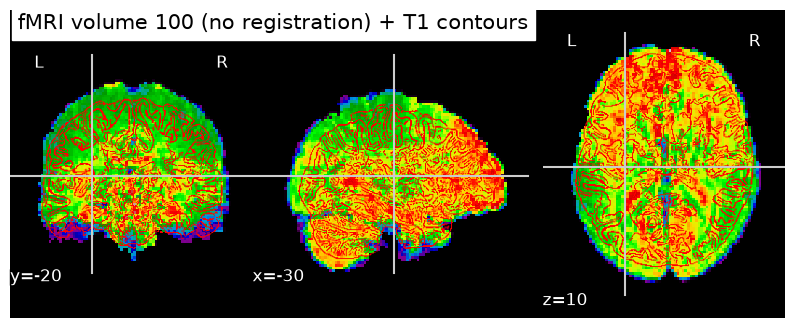

In [20]:
print("fMRI affine:\n", nib.load(MOCO_PATH + ".nii.gz").affine)
print("T1 affine:\n", nib.load(ANAT_PATH).affine)

vol = 100
fmri_vol = image.index_img(MOCO_PATH + ".nii.gz", vol)
fig, ax = plt.subplots(figsize=(10, 4))
d = plotting.plot_epi(fmri_vol, cut_coords=cuts, axes=ax,
                      title=f"fMRI volume {vol} (no registration) + T1 contours")
d.add_edges(betted_brain + ".nii.gz")
plt.savefig(op.join(FIG_DIR, "2c_overlay.png"), dpi=200, bbox_inches="tight")

In [21]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(ANAT_PATH)
fsleyesDisplay.load(MOCO_PATH)